# T21 -- Forward propagation orchestration, manual check

**Scope.** This notebook is a visualization/inspection artifact only. No scientific
logic is reimplemented -- the forward run itself is computed entirely by
`iste.forward_propagation.forward_propagate_candidate` (T21), which in turn calls
T20's `iste.forward_transport.forward_euler_maruyama_step` and T08/T09's existing
`iste.forcing_ensemble`/`iste.ensemble_run.make_perturbed_source`. No predicted-slick
KDE, forward error metric, or `c_hat*` is computed anywhere here (T22/T23).

**What this demonstrates.** One synthetic candidate core (15 particles, standing in
for a real T14 -> ... -> T19 chain's output -- this notebook is about T21's own
orchestration and visualization, not about re-deriving a candidate from scratch) is
forward-propagated from `t_s` to `t_obs` under THREE forcing members independently,
via one call to `forward_propagate_candidate`. The figure shows:

- the candidate's starting core (open circles, at `t_s`);
- every particle's full trajectory line, one color per forcing member;
- each member's final positions at `t_obs` (filled circles, same color).

In [1]:
import os, sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import matplotlib.pyplot as plt
import numpy as np

from iste.core_sampling import SampledCoreParticles
from iste.environment import GriddedFieldSource
from iste.forcing_ensemble import ForcingEnsemble, ForcingEnsembleConfig
from iste.forward_propagation import forward_propagate_candidate

## 1. Synthetic ocean field and forcing ensemble

A small synthetic grid with a steady eastward/northward current, plus T08's
`ForcingEnsemble` (unmodified) to give each forcing member its own coherent
perturbation -- so the three members' trajectories visibly diverge.

In [2]:
NAT = np.datetime64("NaT", "ns")
LAT = np.linspace(15.0, 25.0, 21)
LON = np.linspace(95.0, 108.0, 27)
T_S = np.datetime64("2020-01-01T00:00", "ns")
N_HOURS = 12
TIME = T_S + np.arange(N_HOURS) * np.timedelta64(3600, "s")
T_OBS = T_S + np.timedelta64(6, "h")
DT = 900.0  # 15 minutes

uo = np.full((N_HOURS, len(LAT), len(LON)), 0.35)  # steady eastward current
vo = np.full((N_HOURS, len(LAT), len(LON)), 0.10)  # steady northward current
ocean = GriddedFieldSource(
    source_path="<synthetic>", time_name="time", time=TIME, lat_name="lat", lat=LAT,
    lon_name="lon", lon=LON, data={"uo": uo, "vo": vo}, fill_threshold=1e19,
)
ensemble_config = ForcingEnsembleConfig(
    n_members=4, spatial_correlation_km=40.0, correlation_time_seconds=2 * 3600.0,
    sigma_u=0.15, coarse_resolution_deg=0.5, master_seed=77,
)
ensemble = ForcingEnsemble(ocean, ensemble_config)
K = np.full((len(LAT), len(LON)), 3.0)

## 2. Candidate core (synthetic T19 output)

15 particles clustered near (18.0N, 100.0E) at `t_s` -- a `SampledCoreParticles`
record built directly with the exact fields T19 produces, so
`forward_propagate_candidate` sees the same input shape it would from a real
T14->T19 chain.

In [3]:
rng = np.random.default_rng(5)
n = 15
lat0 = 18.0 + rng.normal(0.0, 0.05, n)
lon0 = 100.0 + rng.normal(0.0, 0.05, n)
particle_id = np.array([f"p{i:02d}" for i in range(n)], dtype=object)
observation_pixel_id = np.array([f"px-{i % 3}" for i in range(n)], dtype=object)
forcing_member_id = np.zeros(n, dtype=np.int64)  # original Stage III provenance (demo: all member 0)
log_weight = rng.normal(0.0, 0.3, n)

sampled = SampledCoreParticles(
    candidate_id="2020-01-01T00:00:00_cand000", t_s=T_S, X=n, Y=n, N_forward=n,
    forward_validatable=True, resampled=False, sampling_seed=0,
    particle_id=particle_id, observation_pixel_id=observation_pixel_id,
    forcing_member_id=forcing_member_id, lat=lat0, lon=lon0, log_weight=log_weight,
    valid=np.ones(n, dtype=bool),
    death_time=np.full(n, NAT, dtype="datetime64[ns]"),
    death_lat=np.full(n, np.nan), death_lon=np.full(n, np.nan),
    death_reason=np.array([""] * n, dtype=object),
)
print(f"candidate {sampled.candidate_id}: {sampled.n_selected} core particles at t_s={T_S}")

candidate 2020-01-01T00:00:00_cand000: 15 core particles at t_s=2020-01-01T00:00:00.000000000


## 3. T21 forward propagation under 3 forcing members

One call to `forward_propagate_candidate` -- it builds each member's perturbed
`U_e` field once (T08/T09, reused unchanged for that member's entire run) and
loops T20's single-step operator from `t_s` to exactly `t_obs`.

In [4]:
MEMBER_IDS = [0, 1, 2]
SEEDS = [10, 20, 30]
result = forward_propagate_candidate(
    sampled, T_OBS, DT, ocean, ensemble, forcing_member_ids=MEMBER_IDS, seeds=SEEDS,
    k_lat=LAT, k_lon=LON, k_field=K,
)
for m in MEMBER_IDS:
    run = result[m]
    print(f"member {m}: n_steps={run.n_steps} final t={run.timestamps[-1]} "
          f"mean final lat/lon=({run.final_lat.mean():.3f},{run.final_lon.mean():.3f}) "
          f"n_valid_final={run.final_valid.sum()}")
assert result.forcing_member_ids == tuple(MEMBER_IDS)
assert all(result[m].timestamps[-1] == T_OBS for m in MEMBER_IDS)  # stops exactly at t_obs

member 0: n_steps=24 final t=2020-01-01T06:00:00.000000000 mean final lat/lon=(18.025,100.052) n_valid_final=15
member 1: n_steps=24 final t=2020-01-01T06:00:00.000000000 mean final lat/lon=(18.028,100.046) n_valid_final=15
member 2: n_steps=24 final t=2020-01-01T06:00:00.000000000 mean final lat/lon=(18.007,100.051) n_valid_final=15


## 4. Visualization: starting core, per-member trajectories, final positions

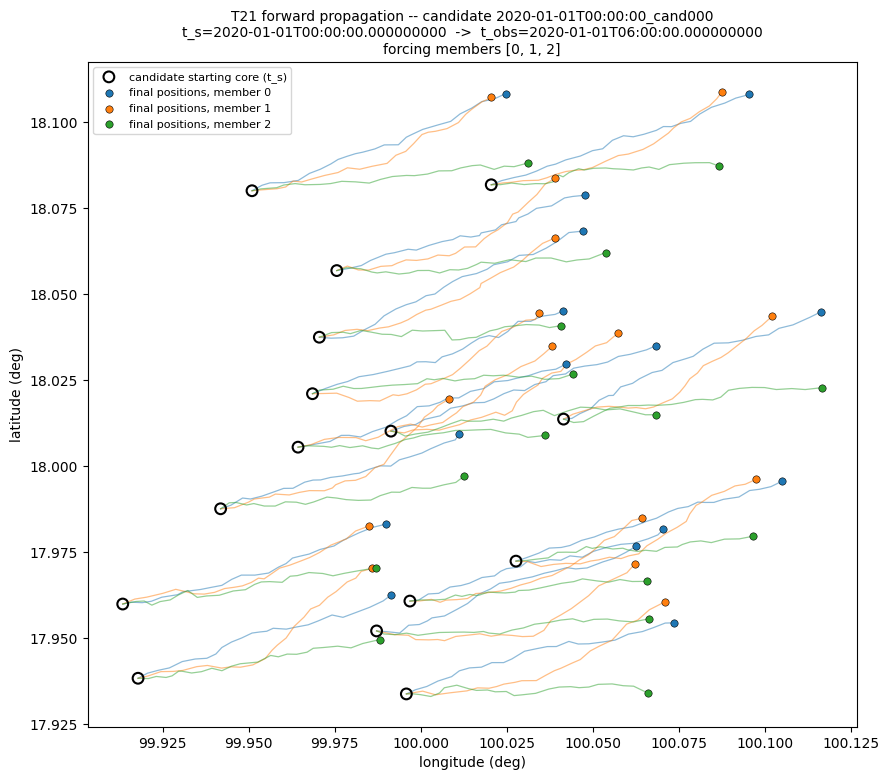

In [5]:
colors = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}
fig, ax = plt.subplots(figsize=(9, 8))

ax.scatter(sampled.lon, sampled.lat, s=60, marker="o", facecolors="none",
           edgecolors="black", linewidths=1.5, zorder=5, label="candidate starting core (t_s)")

for m in MEMBER_IDS:
    run = result[m]
    for p in range(run.n_particles):
        ax.plot(run.lon[:, p], run.lat[:, p], color=colors[m], alpha=0.5, linewidth=0.9, zorder=2)
    ax.scatter(run.final_lon, run.final_lat, s=28, color=colors[m], edgecolors="black",
               linewidths=0.4, zorder=4, label=f"final positions, member {m}")

ax.set_xlabel("longitude (deg)")
ax.set_ylabel("latitude (deg)")
ax.set_title(
    f"T21 forward propagation -- candidate {sampled.candidate_id}\n"
    f"t_s={T_S}  ->  t_obs={T_OBS}\nforcing members {MEMBER_IDS}",
    fontsize=10,
)
ax.legend(loc="upper left", fontsize=8)
ax.set_aspect("equal")
fig.tight_layout()
plt.show()

## Interpretation limits

- This is a **forward-propagation** artifact, not a predicted-slick comparison. No
  KDE/footprint construction (T22) or forward error/consistency metric (T23) is
  computed here.
- The three trajectory colors show forcing-member DIVERGENCE (each member's own
  coherent, independently-perturbed `U_e`), not uncertainty in a statistical sense --
  `ForcingEnsemble` remains a labeled PROTOTYPE, not a validated model-error estimate
  (see `iste/forcing_ensemble.py`'s own module docstring).
- Every particle's `forcing_member_id` shown here is its ORIGINAL Stage III
  provenance (all `0` in this synthetic demo) -- it is NOT the forward member each
  trajectory color represents; those are two deliberately distinct concepts (see
  `memory.md`'s T20/T21 entries).
- The run stops exactly at `t_obs` for every member (asserted above), never
  overshooting or silently terminating early.